In [ ]:
# Cell 1 - Imporing Libraries
import os, sys, random, cv2, torch, numpy as np, matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms
from torchvision.datasets import FashionMNIST

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Python: 3.12.13
PyTorch: 2.10.0+cu128
CUDA available: True
GPU: NVIDIA RTX PRO 6000 Blackwell Server Edition


In [ ]:
# Cell 2 — Config, seed, device, folders

CONFIG = {
    "image_size": 256,
    "canny_low": 100,
    "canny_high": 200,
    "seed": 42,
    "selected_labels": [3, 7],   # dress, sneaker
    "max_training_steps": 3000,
    "batch_size": 2
}

random.seed(CONFIG["seed"])
np.random.seed(CONFIG["seed"])
torch.manual_seed(CONFIG["seed"])
if torch.cuda.is_available():
    torch.cuda.manual_seed(CONFIG["seed"])

device = "cuda" if torch.cuda.is_available() else "cpu"

os.makedirs("outputs", exist_ok=True)
os.makedirs("checkpoints", exist_ok=True)

print("Device:", device)
print("Selected labels:", CONFIG["selected_labels"])
print("Folders ready.")

Device: cuda
Selected labels: [3, 7]
Folders ready.


In [ ]:
# Cell 3 - Saving of images
def save_image(tensor, path):
    image = tensor.detach().cpu()
    image = ((image + 1) / 2).clamp(0, 1)
    image = (image.permute(1, 2, 0).numpy() * 255).astype("uint8")
    Image.fromarray(image).save(path)

print("save_image() ready")

save_image() ready


Filtered training samples: 12000
Filtered testing samples: 2000


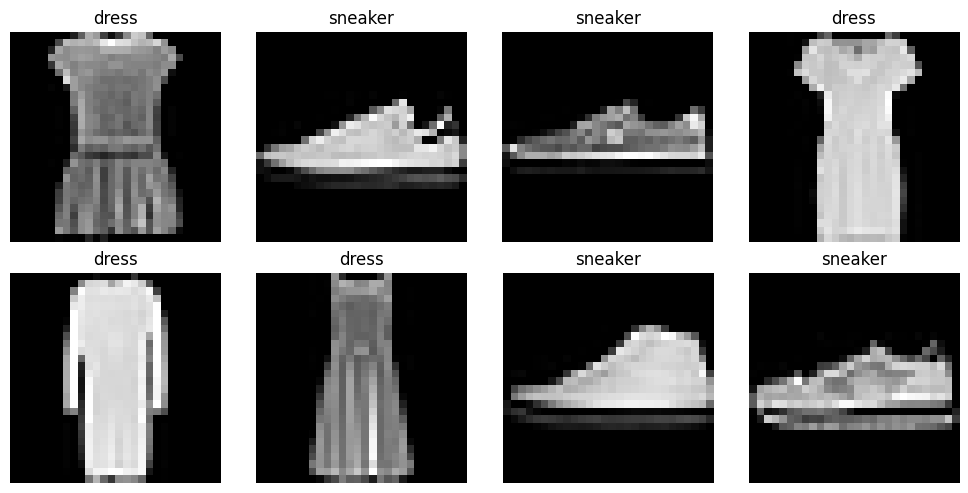

In [ ]:
# Cell 4 — Load Fashion-MNIST and filter to selected labels

full_train_data = FashionMNIST(root="./data", train=True, download=True, transform=transforms.ToTensor())
full_test_data  = FashionMNIST(root="./data", train=False, download=True, transform=transforms.ToTensor())

selected_labels = CONFIG["selected_labels"]

train_indices = [i for i, (_, label) in enumerate(full_train_data) if label in selected_labels]
test_indices  = [i for i, (_, label) in enumerate(full_test_data) if label in selected_labels]

from torch.utils.data import Subset
train_data = Subset(full_train_data, train_indices)
test_data  = Subset(full_test_data, test_indices)

label_to_name = {
    3: "dress",
    7: "sneaker"
}

print("Filtered training samples:", len(train_data))
print("Filtered testing samples:", len(test_data))

# visualize filtered raw samples
plt.figure(figsize=(10, 5))
for i in range(8):
    img, label = train_data[i]
    plt.subplot(2, 4, i + 1)
    plt.imshow(img.squeeze(), cmap="gray")
    plt.title(label_to_name[label])
    plt.axis("off")
plt.tight_layout()
plt.show()

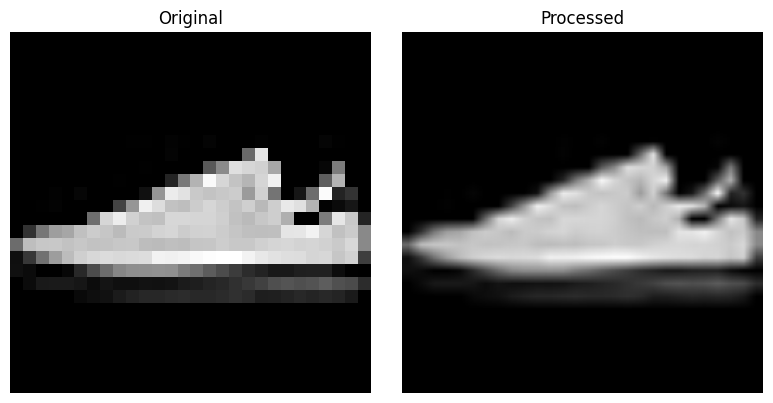

Processed shape: torch.Size([3, 256, 256])


In [ ]:
# Cell 5 - Preprocessing

preprocess = transforms.Compose([
    transforms.Resize((CONFIG["image_size"], CONFIG["image_size"])),
    transforms.Lambda(lambda img: img.convert("RGB")),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3)
])

sample_img, _ = train_data[1]
sample_pil = transforms.ToPILImage()(sample_img)
processed_img = preprocess(sample_pil)

plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
plt.imshow(sample_img.squeeze(), cmap="gray")
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(((processed_img.permute(1, 2, 0).numpy()) + 1) / 2)
plt.title("Processed")
plt.axis("off")
plt.tight_layout()
plt.show()

print("Processed shape:", processed_img.shape)

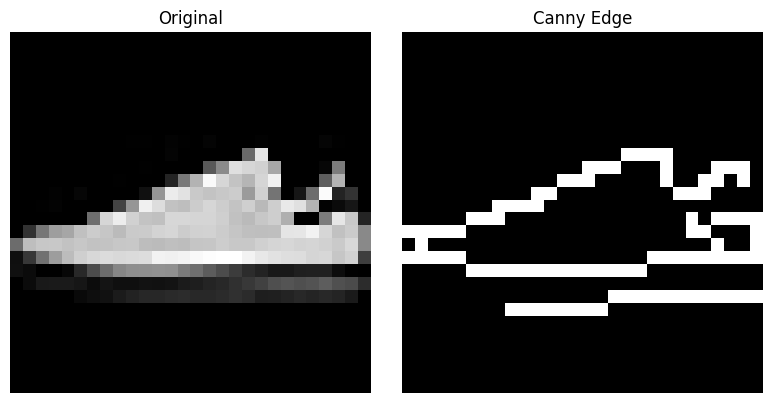

In [ ]:
# Cell 6 - Canny Edge Detection

def generate_canny_edge(pil_img):
    gray = np.array(pil_img.convert("L"))
    edges = cv2.Canny(gray, CONFIG["canny_low"], CONFIG["canny_high"])
    return Image.fromarray(edges)

edge_img = generate_canny_edge(sample_pil)

plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
plt.imshow(sample_pil, cmap="gray")
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(edge_img, cmap="gray")
plt.title("Canny Edge")
plt.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
# Cell 7 — Final dataset with image + edge map + prompt (2-label version)

from torch.utils.data import Dataset, DataLoader, random_split

def make_prompt(label):
    if label == 3:
        return "a dress, fashion product photo, studio lighting, high quality"
    elif label == 7:
        return "a sneaker, fashion product photo, studio lighting, high quality"

class FashionSketchDataset(Dataset):
    def __init__(self, dataset):
        self.dataset = dataset

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        img, label = self.dataset[idx]
        pil_img = transforms.ToPILImage()(img)

        target = preprocess(pil_img)
        edge = preprocess(generate_canny_edge(pil_img))
        prompt = make_prompt(label)

        return {
            "image": target,
            "edge": edge,
            "prompt": prompt,
            "label": label
        }

# split filtered train_data
train_size = int(0.8 * len(train_data))
val_size = len(train_data) - train_size
train_split, val_split = random_split(train_data, [train_size, val_size])

train_dataset = FashionSketchDataset(train_split)
val_dataset   = FashionSketchDataset(val_split)
test_dataset  = FashionSketchDataset(test_data)

train_loader = DataLoader(train_dataset, batch_size=CONFIG["batch_size"], shuffle=True)
val_loader   = DataLoader(val_dataset, batch_size=CONFIG["batch_size"], shuffle=False)
test_loader  = DataLoader(test_dataset, batch_size=CONFIG["batch_size"], shuffle=False)

print("Train samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))

Train samples: 9600
Validation samples: 2400
Test samples: 2000


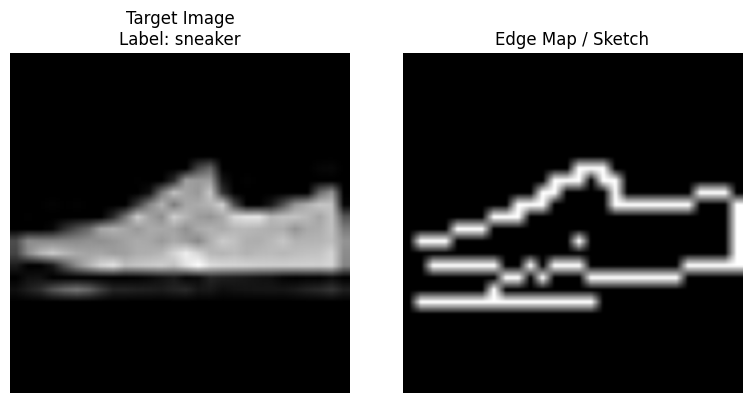

Prompt: a sneaker, fashion product photo, studio lighting, high quality


In [ ]:
# Cell 8 — Visualize one filtered training sample

sample = train_dataset[0] # CHANGE THE NUMBER HERE TO TEST DIFFERENT SAMPLES

image = sample["image"]
edge = sample["edge"]
prompt = sample["prompt"]
label = sample["label"]

image_display = ((image.permute(1, 2, 0).numpy()) + 1) / 2
edge_display = ((edge.permute(1, 2, 0).numpy()) + 1) / 2

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(image_display)
plt.title(f"Target Image\nLabel: {label_to_name[label]}")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(edge_display)
plt.title("Edge Map / Sketch")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Prompt:", prompt)

In [ ]:
# Cell 9 - Loading CED in Pipeline
from diffusers import StableDiffusionControlNetPipeline, ControlNetModel, UniPCMultistepScheduler
import torch

# Use float16 if running on GPU
dtype = torch.float32

# Load ControlNet (Canny)
controlnet = ControlNetModel.from_pretrained(
    "lllyasviel/sd-controlnet-canny",
    torch_dtype=dtype
)

# Load Stable Diffusion v1.5 with ControlNet
pipe = StableDiffusionControlNetPipeline.from_pretrained(
    "runwayml/stable-diffusion-v1-5",
    controlnet=controlnet,
    torch_dtype=dtype,
    safety_checker=None
)

# Replace scheduler for faster and cleaner inference
pipe.scheduler = UniPCMultistepScheduler.from_config(pipe.scheduler.config)

# Move pipeline to GPU/CPU
pipe = pipe.to(device)

print("Stable Diffusion v1.5 + ControlNet loaded successfully.")

Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recomme

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

CLIPTextModel LOAD REPORT from: /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-v1-5/snapshots/451f4fe16113bff5a5d2269ed5ad43b0592e9a14/text_encoder
Key                                | Status     |  | 
-----------------------------------+------------+--+-
text_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
You have disabled the safety checker for <class 'diffusers.pipelines.controlnet.pipeline_controlnet.StableDiffusionControlNetPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results

Stable Diffusion v1.5 + ControlNet loaded successfully.


In [ ]:
# Cell 10 — Pipeline Implementation (ControlNet + UNet + Text Encoder + VAE)

# -------- ControlNet --------
for param in pipe.controlnet.parameters():
    param.requires_grad = True

# -------- UNet --------
for param in pipe.unet.parameters():
    param.requires_grad = True

# -------- Text Encoder --------
for param in pipe.text_encoder.parameters():
    param.requires_grad = True

# -------- VAE (FULL UNFREEZE) --------
for param in pipe.vae.parameters():
    param.requires_grad = True

# Set training mode
pipe.controlnet.train()
pipe.unet.train()
pipe.text_encoder.train()
pipe.vae.train()

# Print stats
trainable_controlnet = sum(p.numel() for p in pipe.controlnet.parameters() if p.requires_grad)
trainable_unet = sum(p.numel() for p in pipe.unet.parameters() if p.requires_grad)
trainable_text = sum(p.numel() for p in pipe.text_encoder.parameters() if p.requires_grad)
trainable_vae = sum(p.numel() for p in pipe.vae.parameters() if p.requires_grad)

print("ControlNet trainable params:", trainable_controlnet)
print("UNet trainable params:", trainable_unet)
print("Text encoder trainable params:", trainable_text)
print("VAE trainable params:", trainable_vae)
print("⚠️ FULL MODEL UNFROZEN (high memory + unstable risk)")

ControlNet trainable params: 361279120
UNet trainable params: 859520964
Text encoder trainable params: 123060480
VAE trainable params: 83653863
⚠️ FULL MODEL UNFROZEN (high memory + unstable risk)


In [ ]:
# Cell 11 — Optimizer

import torch.optim as optim

optimizer = optim.AdamW(
    [
        {"params": pipe.controlnet.parameters(), "lr": 1e-6},
        {"params": pipe.unet.parameters(), "lr": 5e-7},
        {"params": pipe.text_encoder.parameters(), "lr": 5e-7},
        {"params": pipe.vae.parameters(), "lr": 1e-7},  # ⚠️ VERY LOW LR
    ],
    betas=(0.9, 0.999),
    weight_decay=1e-2
)

print("Optimizer created successfully.")
for i, group in enumerate(optimizer.param_groups):
    print(f"Group {i+1} LR:", group["lr"])

Optimizer created successfully.
Group 1 LR: 1e-06
Group 2 LR: 5e-07
Group 3 LR: 5e-07
Group 4 LR: 1e-07


In [ ]:
# Cell 12 — Resume training

import os
import re
import torch

checkpoint_dir = "checkpoints"

resume_epoch = 0
resume_global_step = 0
resume_step_in_epoch = 0

if not os.path.exists(checkpoint_dir):
    os.makedirs(checkpoint_dir)

checkpoint_files = [
    f for f in os.listdir(checkpoint_dir)
    if f.startswith("full_epoch_") and f.endswith(".pt")
]

def extract_ckpt_info(filename):
    m = re.search(r"full_epoch_(\d+)_step_(\d+)(?:_last)?\.pt", filename)
    if m:
        epoch_num = int(m.group(1))
        step_num = int(m.group(2))
        return (epoch_num, step_num)
    return (0, 0)

checkpoint_files.sort(key=extract_ckpt_info, reverse=True)

loaded = False

for ckpt_file in checkpoint_files:
    checkpoint_path = os.path.join(checkpoint_dir, ckpt_file)

    try:
        checkpoint = torch.load(checkpoint_path, map_location=device)

        pipe.controlnet.load_state_dict(checkpoint["controlnet_state_dict"])
        pipe.unet.load_state_dict(checkpoint["unet_state_dict"])
        pipe.text_encoder.load_state_dict(checkpoint["text_encoder_state_dict"])
        pipe.vae.load_state_dict(checkpoint["vae_state_dict"])
        optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

        resume_epoch = checkpoint["epoch"]
        resume_global_step = checkpoint["global_step"]
        resume_step_in_epoch = checkpoint["step_in_epoch"]

        print(f"Resumed from checkpoint: {ckpt_file}")
        print(f"Resume epoch: {resume_epoch}")
        print(f"Resume global step: {resume_global_step}")
        print(f"Resume step in epoch: {resume_step_in_epoch}")

        loaded = True
        break

    except Exception as e:
        print(f"Skipping corrupted checkpoint: {ckpt_file}")
        print("Error:", e)

if not loaded:
    print("No valid FULL-VAE checkpoint found. Starting from epoch 0, step 0.")

Resumed from checkpoint: full_epoch_2_step_4800_last.pt
Resume epoch: 2
Resume global step: 9600
Resume step in epoch: 0


In [ ]:
# Cell 13 — Prepare noise scheduler for diffusion training

from diffusers import DDPMScheduler

noise_scheduler = DDPMScheduler.from_pretrained(
    "runwayml/stable-diffusion-v1-5",
    subfolder="scheduler"
)

print("Noise scheduler loaded successfully.")
print("Number of training timesteps:", noise_scheduler.config.num_train_timesteps)

Noise scheduler loaded successfully.
Number of training timesteps: 1000


In [ ]:
# Cell 14 — Training loop

tokenizer = pipe.tokenizer
text_encoder = pipe.text_encoder

num_epochs = 3
save_every_steps = 2000

global_step = resume_global_step
loss_history = []

pipe.controlnet.train()
pipe.unet.train()
pipe.text_encoder.train()
pipe.vae.train()

for epoch in range(resume_epoch, num_epochs):
    print(f"\nStarting Epoch {epoch + 1}/{num_epochs}")

    start_batch_idx = resume_step_in_epoch if epoch == resume_epoch else 0
    step_in_epoch = start_batch_idx

    for batch_idx, batch in enumerate(train_loader):
        if batch_idx < start_batch_idx:
            continue

        optimizer.zero_grad()

        images = batch["image"].to(device=device, dtype=dtype)

        latents = pipe.vae.encode(images).latent_dist.sample()
        latents = latents * pipe.vae.config.scaling_factor

        noise = torch.randn_like(latents)

        timesteps = torch.randint(
            0,
            noise_scheduler.config.num_train_timesteps,
            (latents.shape[0],),
            device=device
        ).long()

        noisy_latents = noise_scheduler.add_noise(latents, noise, timesteps)

        tokens = tokenizer(
            batch["prompt"],
            padding="max_length",
            truncation=True,
            max_length=tokenizer.model_max_length,
            return_tensors="pt"
        )

        input_ids = tokens.input_ids.to(device)

        text_embeddings = text_encoder(input_ids)[0]

        edge_maps = batch["edge"].to(device=device, dtype=dtype)
        control_image = (edge_maps + 1) / 2

        down_block_res_samples, mid_block_res_sample = pipe.controlnet(
            noisy_latents,
            timesteps,
            encoder_hidden_states=text_embeddings,
            controlnet_cond=control_image,
            return_dict=False
        )

        noise_pred = pipe.unet(
            noisy_latents,
            timesteps,
            encoder_hidden_states=text_embeddings,
            down_block_additional_residuals=down_block_res_samples,
            mid_block_additional_residual=mid_block_res_sample,
            return_dict=False
        )[0]

        if not torch.isfinite(noise_pred).all():
            print("NaN or Inf detected in noise prediction. Stopping training.")
            break

        loss = torch.nn.functional.mse_loss(noise_pred.float(), noise.float())

        if not torch.isfinite(loss):
            print("NaN or Inf detected in loss. Stopping training.")
            break

        loss.backward()

        # Gradient clipping
        torch.nn.utils.clip_grad_norm_(pipe.controlnet.parameters(), 1.0)
        torch.nn.utils.clip_grad_norm_(pipe.unet.parameters(), 1.0)
        torch.nn.utils.clip_grad_norm_(pipe.text_encoder.parameters(), 1.0)
        torch.nn.utils.clip_grad_norm_(pipe.vae.parameters(), 1.0)

        optimizer.step()

        global_step += 1
        step_in_epoch = batch_idx + 1
        loss_history.append(loss.item())

        if global_step % 200 == 0:
            print(
                f"Epoch {epoch + 1}/{num_epochs} | "
                f"Batch {step_in_epoch}/{len(train_loader)} | "
                f"Global Step {global_step} | "
                f"Loss: {loss.item():.4f}"
            )

        # Save checkpoint every 2000 steps inside each epoch
        if step_in_epoch % save_every_steps == 0:
            checkpoint_path = f"checkpoints/full_epoch_{epoch+1}_step_{step_in_epoch}.pt"

            torch.save({
                "epoch": epoch,
                "global_step": global_step,
                "step_in_epoch": step_in_epoch,
                "controlnet_state_dict": pipe.controlnet.state_dict(),
                "unet_state_dict": pipe.unet.state_dict(),
                "text_encoder_state_dict": pipe.text_encoder.state_dict(),
                "vae_state_dict": pipe.vae.state_dict(),
                "optimizer_state_dict": optimizer.state_dict()
            }, checkpoint_path)

            print(f"Checkpoint saved: {checkpoint_path}")

    # Save end-of-epoch checkpoint
    epoch_checkpoint_path = f"checkpoints/full_epoch_{epoch+1}_step_{step_in_epoch}_last.pt"
    torch.save({
        "epoch": epoch + 1,
        "global_step": global_step,
        "step_in_epoch": 0,
        "controlnet_state_dict": pipe.controlnet.state_dict(),
        "unet_state_dict": pipe.unet.state_dict(),
        "text_encoder_state_dict": pipe.text_encoder.state_dict(),
        "vae_state_dict": pipe.vae.state_dict(),
        "optimizer_state_dict": optimizer.state_dict()
    }, epoch_checkpoint_path)

    print(f"End-of-epoch checkpoint saved: {epoch_checkpoint_path}")

    # Reset resume step after first resumed epoch completes
    resume_step_in_epoch = 0

print("Training completed.")


Starting Epoch 3/3
Epoch 3/3 | Batch 200/4800 | Global Step 9800 | Loss: 0.0475
Epoch 3/3 | Batch 400/4800 | Global Step 10000 | Loss: 0.0002
Epoch 3/3 | Batch 600/4800 | Global Step 10200 | Loss: 0.0020
Epoch 3/3 | Batch 800/4800 | Global Step 10400 | Loss: 0.0135
Epoch 3/3 | Batch 1000/4800 | Global Step 10600 | Loss: 0.0111
Epoch 3/3 | Batch 1200/4800 | Global Step 10800 | Loss: 0.0025
Epoch 3/3 | Batch 1400/4800 | Global Step 11000 | Loss: 0.0084
Epoch 3/3 | Batch 1600/4800 | Global Step 11200 | Loss: 0.0031
Epoch 3/3 | Batch 1800/4800 | Global Step 11400 | Loss: 0.0217
Epoch 3/3 | Batch 2000/4800 | Global Step 11600 | Loss: 0.0007
Checkpoint saved: checkpoints/full_epoch_3_step_2000.pt
Epoch 3/3 | Batch 2200/4800 | Global Step 11800 | Loss: 0.0015
Epoch 3/3 | Batch 2400/4800 | Global Step 12000 | Loss: 0.0038
Epoch 3/3 | Batch 2600/4800 | Global Step 12200 | Loss: 0.0069
Epoch 3/3 | Batch 2800/4800 | Global Step 12400 | Loss: 0.0079
Epoch 3/3 | Batch 3000/4800 | Global Step 12600

  0%|          | 0/30 [00:00<?, ?it/s]

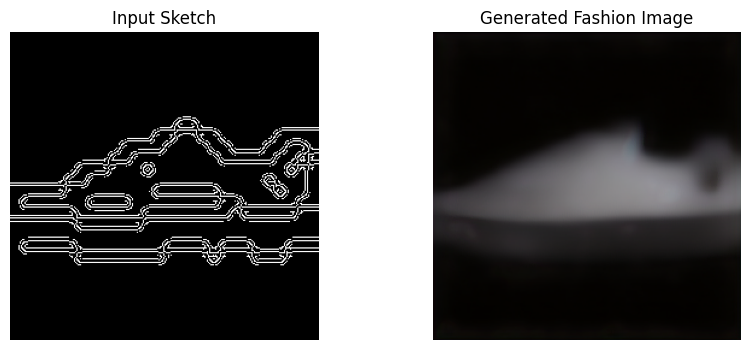

Generated image saved to outputs/generated_sample.png


In [ ]:
# Cell 15 — Generate fashion image from filtered test sketch

def generate_from_sketch(sketch_pil, prompt, steps=30, guidance=7.5):
    edge_img = generate_canny_edge(sketch_pil)
    edge_img = edge_img.resize((CONFIG["image_size"], CONFIG["image_size"]))

    result = pipe(
        prompt=prompt,
        image=edge_img,
        num_inference_steps=steps,
        guidance_scale=guidance
    ).images[0]

    return edge_img, result

test_sample = test_dataset[0] # CHANGE THE NUMBER HERE TO TEST DIFFERENT SAMPLES

sketch_input = transforms.ToPILImage()(test_sample["edge"])
prompt = test_sample["prompt"]

edge, generated = generate_from_sketch(sketch_input, prompt)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(edge, cmap="gray")
plt.title("Input Sketch")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(generated)
plt.title("Generated Fashion Image")
plt.axis("off")

plt.show()

generated.save("outputs/generated_sample.png")
print("Generated image saved to outputs/generated_sample.png")

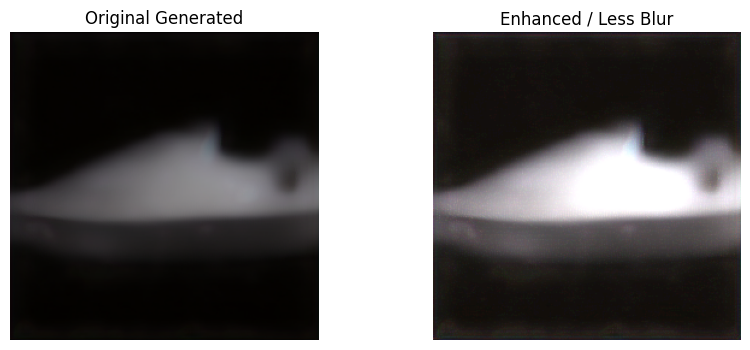

In [ ]:
# Cell 16 — Strong blur reduction using Laplacian sharpening

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load generated image
img = cv2.imread("outputs/generated_sample.png")
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# -------- Step 1: Unsharp masking --------
blur = cv2.GaussianBlur(img, (0,0), sigmaX=1.2, sigmaY=1.2)
sharp = cv2.addWeighted(img, 1.8, blur, -0.8, 0)

# -------- Step 2: Laplacian edge enhancement --------
laplacian = cv2.Laplacian(sharp, cv2.CV_64F)
laplacian = cv2.convertScaleAbs(laplacian)

enhanced = cv2.addWeighted(sharp, 1.5, laplacian, 0.5, 0)

# -------- Step 3: Improve contrast --------
alpha = 1.3
beta = 10
enhanced = cv2.convertScaleAbs(enhanced, alpha=alpha, beta=beta)

# Save result
cv2.imwrite("outputs/generated_sample_sharp.png", cv2.cvtColor(enhanced, cv2.COLOR_RGB2BGR))

# Show comparison
plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.imshow(img)
plt.title("Original Generated")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(enhanced)
plt.title("Enhanced / Less Blur")
plt.axis("off")

plt.show()

SSIM Score: 0.2217


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIPModel LOAD REPORT from: openai/clip-vit-base-patch32
Key                                  | Status     |  | 
-------------------------------------+------------+--+-
text_model.embeddings.position_ids   | UNEXPECTED |  | 
vision_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
The image processor of type `CLIPImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. 


CLIP Score: 0.2021


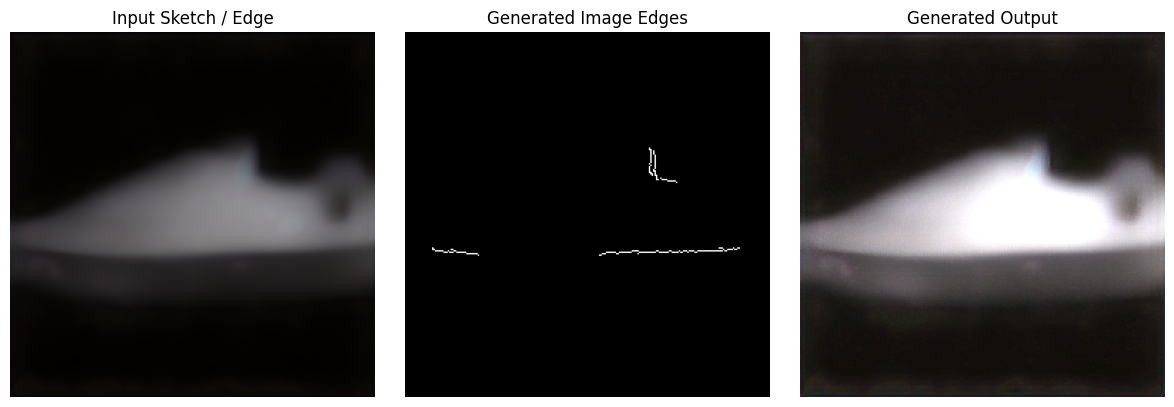

In [ ]:
# Cell 17 — Evaluate generated image using proper SSIM and CLIP Score

from skimage.metrics import structural_similarity as ssim
from transformers import CLIPProcessor, CLIPModel

input_edge = Image.open("outputs/generated_sample.png").convert("RGB")
generated_img = Image.open("outputs/generated_sample_sharp.png").convert("RGB")

eval_size = 256
input_edge_resized = input_edge.resize((eval_size, eval_size))
generated_resized = generated_img.resize((eval_size, eval_size))

generated_gray = cv2.cvtColor(np.array(generated_resized), cv2.COLOR_RGB2GRAY)
generated_edges = cv2.Canny(generated_gray, CONFIG["canny_low"], CONFIG["canny_high"])

input_gray = cv2.cvtColor(np.array(input_edge_resized), cv2.COLOR_RGB2GRAY)

ssim_score = ssim(input_gray, generated_edges)
print("SSIM Score:", round(ssim_score, 4))

clip_model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device)
clip_processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

sample_prompt = test_dataset[0]["prompt"]

inputs = clip_processor(
    text=[sample_prompt],
    images=generated_resized,
    return_tensors="pt",
    padding=True
).to(device)

with torch.no_grad():
    outputs = clip_model(**inputs)
    image_embeds = outputs.image_embeds
    text_embeds = outputs.text_embeds
    clip_score = torch.nn.functional.cosine_similarity(image_embeds, text_embeds).item()

print("CLIP Score:", round(clip_score, 4))

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(input_edge_resized)
plt.title("Input Sketch / Edge")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(generated_edges, cmap="gray")
plt.title("Generated Image Edges")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(generated_resized)
plt.title("Generated Output")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Cell 18 — Create messy sketch version for robustness testing

def make_messy_sketch(edge_pil):
    edge = np.array(edge_pil.convert("L"))

    noise = np.random.randint(0, 50, edge.shape, dtype=np.uint8)
    noisy = cv2.add(edge, noise)

    blurred = cv2.GaussianBlur(noisy, (3, 3), 0)

    kernel = np.ones((2, 2), np.uint8)
    thick = cv2.dilate(blurred, kernel, iterations=1)

    return Image.fromarray(thick)

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

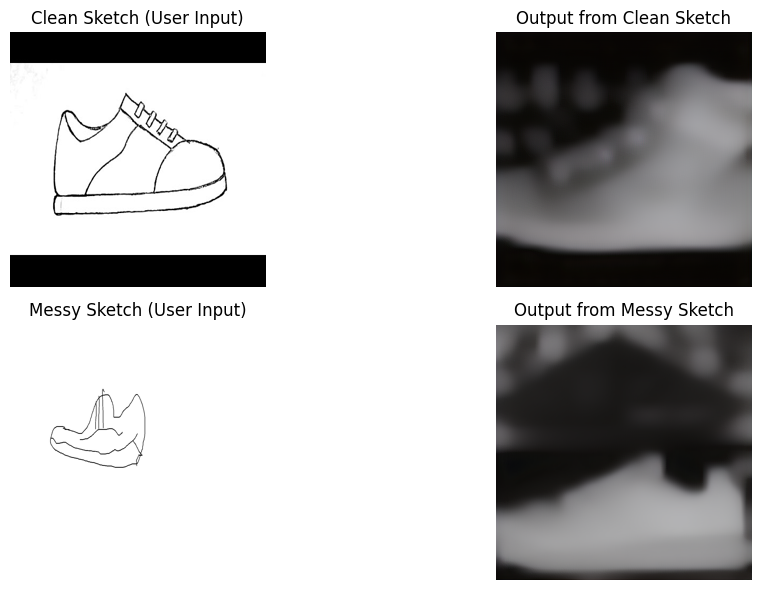

Prompt: a sneaker, fashion product photo, studio lighting, high quality
Saved outputs:
- outputs/clean_input.png
- outputs/messy_input.png
- outputs/clean_output.png
- outputs/messy_output.png


In [ ]:
# Cell 19 — Compare clean vs messy sketch (using TWO different images)

clean_path = "/content/Clean Sketch.jpg"
messy_path = "/content/Sample sketch.png"

# Load sketches
clean_sketch = Image.open(clean_path).convert("RGB")
messy_sketch = Image.open(messy_path).convert("RGB")

# Resize to model input size
clean_sketch = clean_sketch.resize((CONFIG["image_size"], CONFIG["image_size"]))
messy_sketch = messy_sketch.resize((CONFIG["image_size"], CONFIG["image_size"]))

# Prompt
prompt = "a sneaker, fashion product photo, studio lighting, high quality"

# Fix seed for fair comparison
generator_clean = torch.Generator(device=device).manual_seed(42)
generator_messy = torch.Generator(device=device).manual_seed(42)

# Generate outputs
clean_result = pipe(
    prompt=prompt,
    image=clean_sketch,
    num_inference_steps=30,
    guidance_scale=7.5,
    generator=generator_clean
).images[0]

messy_result = pipe(
    prompt=prompt,
    image=messy_sketch,
    num_inference_steps=30,
    guidance_scale=7.5,
    generator=generator_messy
).images[0]

# Save outputs
clean_sketch.save("outputs/clean_input.png")
messy_sketch.save("outputs/messy_input.png")
clean_result.save("outputs/clean_output.png")
messy_result.save("outputs/messy_output.png")

# Display results
plt.figure(figsize=(12, 6))

plt.subplot(2, 2, 1)
plt.imshow(clean_sketch)
plt.title("Clean Sketch (User Input)")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(clean_result)
plt.title("Output from Clean Sketch")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(messy_sketch)
plt.title("Messy Sketch (User Input)")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(messy_result)
plt.title("Output from Messy Sketch")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Prompt:", prompt)
print("Saved outputs:")
print("- outputs/clean_input.png")
print("- outputs/messy_input.png")
print("- outputs/clean_output.png")
print("- outputs/messy_output.png")

In [ ]:
# Cell 20 - Stable Diffusion Pipeline Loading
from diffusers import StableDiffusionPipeline, UniPCMultistepScheduler

base_pipe = StableDiffusionPipeline.from_pretrained(
    "runwayml/stable-diffusion-v1-5",
    torch_dtype=dtype,
    safety_checker=None
)

base_pipe.scheduler = UniPCMultistepScheduler.from_config(base_pipe.scheduler.config)
base_pipe = base_pipe.to(device)

print("Plain Stable Diffusion pipeline loaded successfully.")

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

CLIPTextModel LOAD REPORT from: /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-v1-5/snapshots/451f4fe16113bff5a5d2269ed5ad43b0592e9a14/text_encoder
Key                                | Status     |  | 
-----------------------------------+------------+--+-
text_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its resul

Plain Stable Diffusion pipeline loaded successfully.


In [ ]:
# Cell 21 — Gradio interface using only trained Text + Sketch pipeline

!pip install -q gradio

import gradio as gr
import torch
import numpy as np
from PIL import Image

# Global storage for latest Gradio inputs/outputs
latest_prompt = None
latest_sketch = None
latest_output = None

# Put trained pipeline in eval mode
pipe.controlnet.eval()
pipe.unet.eval()
pipe.text_encoder.eval()
pipe.vae.eval()

def preprocess_uploaded_sketch(input_image):
    if input_image is None:
        raise ValueError("Please upload a sketch image.")

    if isinstance(input_image, np.ndarray):
        sketch = Image.fromarray(input_image).convert("RGB")
    elif isinstance(input_image, Image.Image):
        sketch = input_image.convert("RGB")
    else:
        raise ValueError("Unsupported image format.")

    sketch = sketch.resize((CONFIG["image_size"], CONFIG["image_size"]))
    return sketch

def generate_from_prompt_and_sketch(user_prompt, sketch_image, steps, guidance):
    global latest_prompt, latest_sketch, latest_output

    if user_prompt is None or user_prompt.strip() == "":
        raise ValueError("Please enter a prompt.")

    sketch = preprocess_uploaded_sketch(sketch_image)

    generator = torch.Generator(device=device).manual_seed(42)

    result = pipe(
        prompt=user_prompt,
        image=sketch,
        num_inference_steps=int(steps),
        guidance_scale=float(guidance),
        generator=generator,
        controlnet_conditioning_scale=0.8
    ).images[0]

    # Save latest session values
    latest_prompt = user_prompt
    latest_sketch = sketch
    latest_output = result

    # Also save files
    sketch.save("outputs/latest_gradio_sketch.png")
    result.save("outputs/latest_gradio_output.png")

    return sketch, result

demo = gr.Interface(
    fn=generate_from_prompt_and_sketch,
    inputs=[
        gr.Textbox(
            lines=2,
            placeholder="Enter a prompt like: a realistic white sneaker, side view, product photography, studio lighting, high detail, clean background",
            label="Prompt"
        ),
        gr.Image(type="pil", label="Upload Sketch"),
        gr.Slider(10, 60, value=30, step=1, label="Inference Steps"),
        gr.Slider(1.0, 12.0, value=7.5, step=0.5, label="Guidance Scale"),
    ],
    outputs=[
        gr.Image(type="pil", label="Processed Sketch"),
        gr.Image(type="pil", label="Generated Output"),
    ],
    title="Sketch2Style — Text + Sketch Interface",
    description="Upload a sketch and enter a prompt to generate an image using the trained Sketch2Style pipeline."
)

demo.launch(debug=True)

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://ad474d0d65bb9b92e9.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


ERROR:    Exception in ASGI application
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/uvicorn/protocols/http/httptools_impl.py", line 420, in run_asgi
    result = await app(  # type: ignore[func-returns-value]
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/uvicorn/middleware/proxy_headers.py", line 60, in __call__
    return await self.app(scope, receive, send)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/fastapi/applications.py", line 1163, in __call__
    await super().__call__(scope, receive, send)
  File "/usr/local/lib/python3.12/dist-packages/starlette/applications.py", line 107, in __call__
    await self.middleware_stack(scope, receive, send)
  File "/usr/local/lib/python3.12/dist-packages/starlette/middleware/errors.py", line 186, in __call__
    raise exc
  File "/usr/local/lib/python3.12/dist-packages/starlette/middleware/error

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://ad474d0d65bb9b92e9.gradio.live


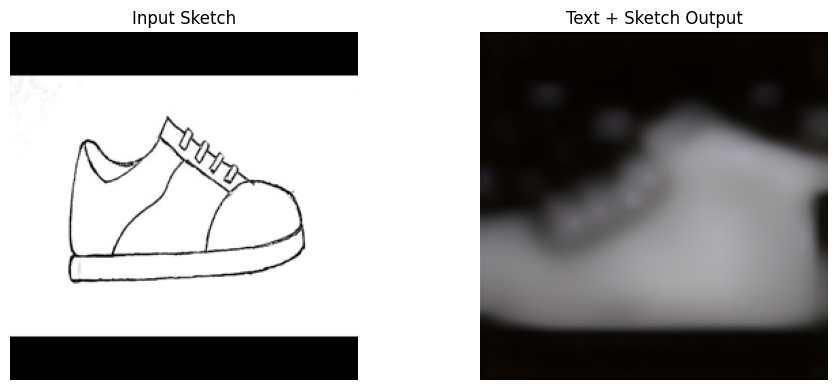

Latest Prompt: a sneaker, fashion product photo, studio lighting, high quality
Saved:
- outputs/text_sketch_input_latest.png
- outputs/text_sketch_output_latest.png


In [ ]:
# Cell 22 — Show latest Gradio Text + Sketch result only

if latest_prompt is None or latest_sketch is None or latest_output is None:
    raise ValueError("No Gradio result found yet. Please run the Gradio interface and generate an image first.")

# Save again if needed
latest_sketch.save("outputs/text_sketch_input_latest.png")
latest_output.save("outputs/text_sketch_output_latest.png")

# Display latest result
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(latest_sketch)
plt.title("Input Sketch")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(latest_output)
plt.title("Text + Sketch Output")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Latest Prompt:", latest_prompt)
print("Saved:")
print("- outputs/text_sketch_input_latest.png")
print("- outputs/text_sketch_output_latest.png")

In [ ]:
# Cell 23 — FID evaluation using ONLY dress + sneaker dataset

!pip install -q pytorch-fid

import os
import shutil
from PIL import Image
import torch

real_dir = "fid_real"
gen_dir = "fid_generated"

# Clean folders
for folder in [real_dir, gen_dir]:
    if os.path.exists(folder):
        shutil.rmtree(folder)
    os.makedirs(folder)

num_samples = 300

count = 0
idx = 0

while count < num_samples and idx < len(test_dataset):

    sample = test_dataset[idx]
    label = sample["label"]

    # Only use dress (3) and sneaker (7)
    if label not in [3, 7]:
        idx += 1
        continue

    # -------- REAL IMAGE --------
    real_tensor = sample["image"].cpu()
    real_img = ((real_tensor + 1) / 2).clamp(0, 1)
    real_img = (real_img.permute(1, 2, 0).numpy() * 255).astype("uint8")
    Image.fromarray(real_img).save(f"{real_dir}/{count}.png")

    # -------- GENERATE IMAGE --------
    edge_tensor = sample["edge"].cpu()
    edge_img = ((edge_tensor + 1) / 2).clamp(0, 1)
    edge_img = (edge_img.permute(1, 2, 0).numpy() * 255).astype("uint8")
    sketch = Image.fromarray(edge_img)

    prompt = sample["prompt"]

    generator = torch.Generator(device=device).manual_seed(count)

    result = pipe(
        prompt=prompt,
        image=sketch,
        num_inference_steps=25,
        guidance_scale=6.5,
        generator=generator
    ).images[0]

    result.save(f"{gen_dir}/{count}.png")

    count += 1
    idx += 1

print(f"Saved {count} filtered samples for FID")

# -------- Compute FID --------
import subprocess

result = subprocess.run(
    ["python", "-m", "pytorch_fid", real_dir, gen_dir],
    capture_output=True,
    text=True
)

print(result.stdout)

Saved 300 filtered samples for FID
FID:  253.2126846422744



  0%|          | 0/30 [00:00<?, ?it/s]

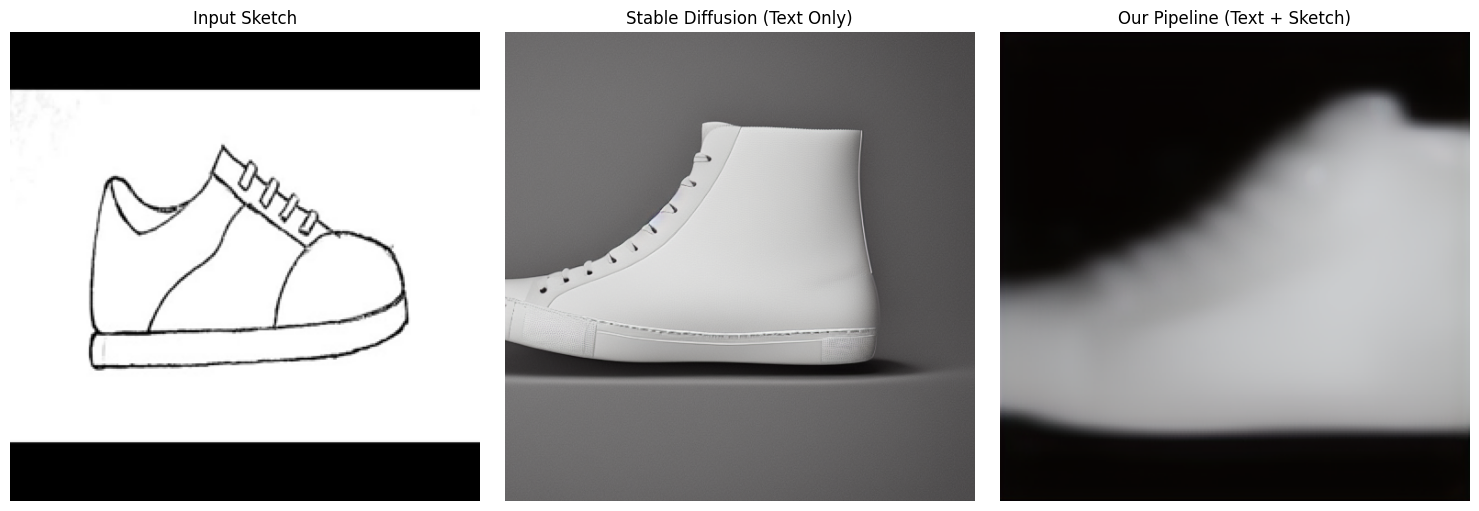

Prompt: a realistic white sneaker, side view, product photography, studio lighting, high detail, clean background
Saved:
- outputs/comparison_input_sketch.png
- outputs/comparison_stable_diffusion.png
- outputs/comparison_our_pipeline.png


In [42]:
# Cell — Stable Diffusion vs Our Sketch2Style Pipeline (same prompt + same sketch)

from PIL import Image
import torch
import matplotlib.pyplot as plt

# -----------------------------
# Use the same sketch image used in Gradio
# -----------------------------
sketch_path = "/content/Clean Sketch.jpg"   # change if needed
prompt = "a realistic white sneaker, side view, product photography, studio lighting, high detail, clean background"

# Load and resize sketch
sketch = Image.open(sketch_path).convert("RGB")
sketch = sketch.resize((CONFIG["image_size"], CONFIG["image_size"]))

# -----------------------------
# Fixed seed for fair comparison
# -----------------------------
seed = 42
generator_sd = torch.Generator(device=device).manual_seed(seed)
generator_ours = torch.Generator(device=device).manual_seed(seed)

# -----------------------------
# 1) Stable Diffusion baseline (text only)
# -----------------------------
sd_result = base_pipe(
    prompt=prompt,
    num_inference_steps=30,
    guidance_scale=7.5,
    generator=generator_sd
).images[0]

# -----------------------------
# 2) Our trained pipeline (text + sketch)
# -----------------------------
ours_result = pipe(
    prompt=prompt,
    image=sketch,
    num_inference_steps=30,
    guidance_scale=7.5,
    generator=generator_ours,
    controlnet_conditioning_scale=0.8
).images[0]

# -----------------------------
# Save outputs
# -----------------------------
sketch.save("outputs/comparison_input_sketch.png")
sd_result.save("outputs/comparison_stable_diffusion.png")
ours_result.save("outputs/comparison_our_pipeline.png")

# -----------------------------
# Display comparison
# -----------------------------
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(sketch)
plt.title("Input Sketch")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(sd_result)
plt.title("Stable Diffusion (Text Only)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(ours_result)
plt.title("Our Pipeline (Text + Sketch)")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Prompt:", prompt)
print("Saved:")
print("- outputs/comparison_input_sketch.png")
print("- outputs/comparison_stable_diffusion.png")
print("- outputs/comparison_our_pipeline.png")

In [ ]:
# Cell 24 — Human-in-the-loop evaluation template

import pandas as pd

user_eval = pd.DataFrame({
    "sample_id": [1, 2, 3, 4, 5, 6],
    "category": ["dress", "dress", "sneaker", "dress", "sneaker", "sneaker"],
    "sketch_following_score_1to5": ["4", "3", "4", "3", "4", "3"],
    "visual_quality_score_1to5": ["2", "3", "2", "3", "2", "3"],
    "prompt_alignment_score_1to5": ["3", "4", "3", "3", "4", "3"],
    "comments": ["Good shape, blurry", "Moderate detail", "Shape preserved", "Some distortion", "Recognizable sneaker", "Low texture quality"]
})

user_eval

,sample_id,category,sketch_following_score_1to5,visual_quality_score_1to5,prompt_alignment_score_1to5,comments
0,1,dress,4,2,3,"Good shape, blurry"
1,2,dress,3,3,4,Moderate detail
2,3,sneaker,4,2,3,Shape preserved
3,4,dress,3,3,3,Some distortion
4,5,sneaker,4,2,4,Recognizable sneaker
5,6,sneaker,3,3,3,Low texture quality
